# Data quality (2022-2023)

Goal: understand the sensor data before writing cleaning rules (EDA steps 0-4).

Each section: question → code → what we found → decision.

Data: data/interim/*.parquet, **2022-2023 only**. 2024 is the locked test year.

In [1]:
import calendar
from datetime import date, datetime, time

import matplotlib.pyplot as plt
import polars as pl

from madrid_congestion.config import DST_ROWS, EDA_YEARS, FIGURES_DIR, INTERIM_DATA_DIR, SAMPLES_FULL, SLOT, URB, K_GRID, MIN_SAMPLES
 
EDA_MONTHS = [f"{year}-{month:02d}" for year in EDA_YEARS for month in range(1, 13)]
SLOTS_PER_DAY = 96
print(len(EDA_MONTHS), EDA_MONTHS[0], EDA_MONTHS[-1], INTERIM_DATA_DIR)

24 2022-01 2023-12 E:\Madrid-traffic-ageing_Advanced project\madrid-congestion\data\interim


## Overview of the data

Look at one month to learn what each column holds before writing any rule.

In [2]:
OVERVIEW_FILE = INTERIM_DATA_DIR / "2022-03.parquet"

pl.scan_parquet(OVERVIEW_FILE).head(10).collect()


id,fecha,tipo_elem,intensidad,ocupacion,carga,vmed,error,periodo_integracion
i32,datetime[μs],str,i32,i16,i16,i16,str,i8
1001,2022-03-01 00:00:00,"""M30""",408,2,0,52,"""N""",5
1001,2022-03-01 00:15:00,"""M30""",336,1,0,38,"""N""",5
1001,2022-03-01 00:30:00,"""M30""",276,2,0,37,"""N""",5
1001,2022-03-01 00:45:00,"""M30""",252,0,0,45,"""N""",5
1001,2022-03-01 01:00:00,"""M30""",312,1,0,51,"""N""",5
1001,2022-03-01 01:15:00,"""M30""",168,null,0,43,"""N""",5
1001,2022-03-01 01:30:00,"""M30""",168,0,0,54,"""N""",5
1001,2022-03-01 01:45:00,"""M30""",120,0,0,48,"""N""",5
1001,2022-03-01 02:00:00,"""M30""",132,1,0,43,"""N""",5


In [3]:
pl.read_parquet_schema(OVERVIEW_FILE)

Schema([('id', Int32),
        ('fecha', Datetime(time_unit='us', time_zone=None)),
        ('tipo_elem', String),
        ('intensidad', Int32),
        ('ocupacion', Int16),
        ('carga', Int16),
        ('vmed', Int16),
        ('error', String),
        ('periodo_integracion', Int8)])

In [4]:
pl.scan_parquet(OVERVIEW_FILE).select(pl.len()).collect()

len
u32
11796900


## First look: availability per month
Before the URB-only and k rules: counts all point types, and "valid" only means a row exists.
Replaced by step 4 (panel). The September 2022 jump is the M30 points returning, not newly installed points.

In [5]:
monthly_tables = []
for month_label in EDA_MONTHS:
    year, month_number = int(month_label[:4]), int(month_label[5:])
    slots_in_month = calendar.monthrange(year, month_number)[1] * SLOTS_PER_DAY
    month_rows = pl.read_parquet(
        INTERIM_DATA_DIR / f"{month_label}.parquet", columns=["id", "ocupacion"]
    )
    per_point = (
        month_rows.group_by("id")
        .agg(slots_with_value=pl.col("ocupacion").count())
        .with_columns(
            month=pl.lit(month_label),
            available_share=pl.col("slots_with_value") / slots_in_month
        )
    )
    monthly_tables.append(per_point)

point_month_availability = pl.concat(monthly_tables)
point_month_availability.describe()

statistic,id,slots_with_value,month,available_share
str,f64,f64,str,f64
"""count""",106281.0,106281.0,"""106281""",106281.0
"""null_count""",0.0,0.0,"""0""",0.0
"""mean""",37816.183137,2761.643963,null,0.945698
"""std""",5.4585e6,462.875967,null,0.155864
"""min""",495.0,1.0,"""2022-01""",0.000336
"""25%""",4597.0,2792.0,null,0.96875
"""50%""",5787.0,2879.0,null,0.994097
"""75%""",7094.0,2964.0,null,0.998958
"""max""",1.1409e9,2976.0,"""2023-12""",1.0


In [6]:
print(point_month_availability.height)
point_month_availability["available_share"].describe()

106281


statistic,value
str,f64
"""count""",106281.0
"""null_count""",0.0
"""mean""",0.945698
"""std""",0.155864
"""min""",0.000336
"""25%""",0.96875
"""50%""",0.994097
"""75%""",0.998958
"""max""",1.0


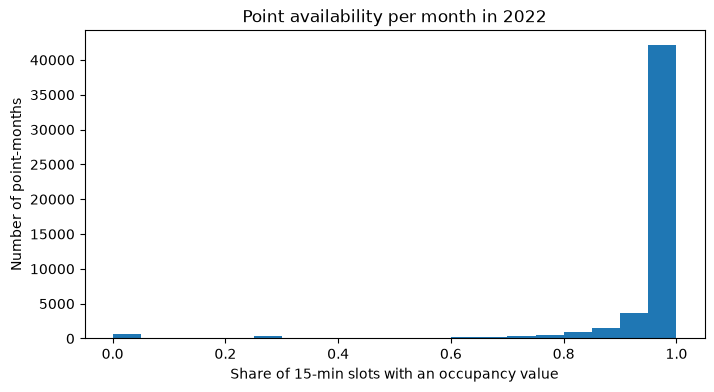

In [7]:
available_share_2022 = point_month_availability.filter(
    pl.col("month").str.starts_with("2022")
)["available_share"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(available_share_2022, bins=20)
ax.set(
    title="Point availability per month in 2022",
    xlabel="Share of 15-min slots with an occupancy value",
    ylabel="Number of point-months",
)
plt.show()

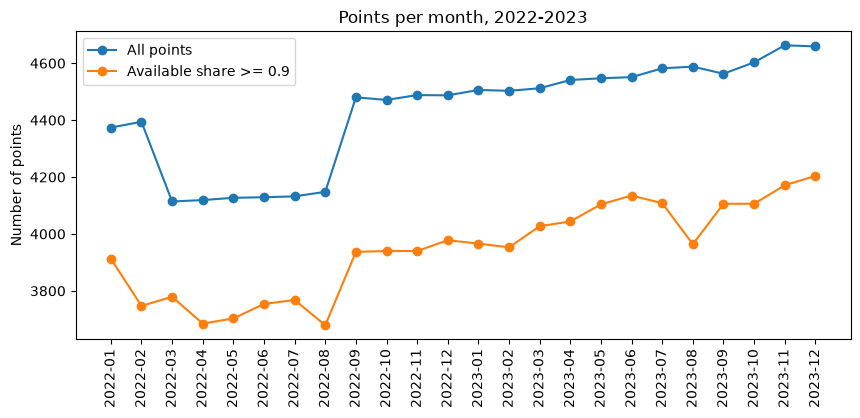

In [8]:
points_per_month = (
    point_month_availability.group_by("month")
    .agg(
        all_points=pl.len(),
        reliable_points=(pl.col("available_share") >= 0.9).sum(),
    )
    .sort("month")
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    points_per_month["month"],
    points_per_month["all_points"],
    marker="o",
    label="All points",
)
ax.plot(
    points_per_month["month"],
    points_per_month["reliable_points"],
    marker="o",
    label="Available share >= 0.9",
)
ax.set(title="Points per month, 2022-2023", ylabel="Number of points")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.show()

## Step 2: Clock changes (DST rows)
Question: which rows do the summer-time changes break, and how do we find them?

Find the clock-change Sundays and check whether they look different from a normal Sunday.

In [9]:
print(calendar.month(2022, 3))
print(calendar.month(2022, 10))
print(calendar.month(2023, 3))
print(calendar.month(2023, 10))

     March 2022
Mo Tu We Th Fr Sa Su
    1  2  3  4  5  6
 7  8  9 10 11 12 13
14 15 16 17 18 19 20
21 22 23 24 25 26 27
28 29 30 31

    October 2022
Mo Tu We Th Fr Sa Su
                1  2
 3  4  5  6  7  8  9
10 11 12 13 14 15 16
17 18 19 20 21 22 23
24 25 26 27 28 29 30
31

     March 2023
Mo Tu We Th Fr Sa Su
       1  2  3  4  5
 6  7  8  9 10 11 12
13 14 15 16 17 18 19
20 21 22 23 24 25 26
27 28 29 30 31

    October 2023
Mo Tu We Th Fr Sa Su
                   1
 2  3  4  5  6  7  8
 9 10 11 12 13 14 15
16 17 18 19 20 21 22
23 24 25 26 27 28 29
30 31



In [10]:
DAYS_TO_COMPARE = {
    "normal Sunday": date(2022, 3, 20),
    "spring change": date(2022, 3, 27),
    "autumn change": date(2022, 10, 30),
}

for label, day in DAYS_TO_COMPARE.items():
    month_file = INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet"
    per_point = (
        pl.read_parquet(month_file, columns=["id", "fecha", "tipo_elem", "periodo_integracion"])
        .filter(pl.col("tipo_elem") == URB, pl.col("fecha").dt.date() == day)
        .group_by("id")
        .agg(rows_that_day=pl.len(), samples_that_day=pl.col("periodo_integracion").sum())
    )
    print(
        f"{label:14} {day} rows: {per_point['rows_that_day'].mode().to_list()}"
        f" samples: {per_point['samples_that_day'].mode().to_list()} points: {per_point.height}"
    )

normal Sunday  2022-03-20 rows: [96] samples: [1440] points: 3940
spring change  2022-03-27 rows: [93] samples: [1378] points: 3946
autumn change  2022-10-30 rows: [96] samples: [1500] points: 3930


Zoom in on the change nights to see which slots are broken.

In [11]:
DST_DAYS = [date(2022, 3, 27), date(2022, 10, 30), date(2023, 3, 26), date(2023, 10, 29)]

for day in DST_DAYS:
    night_summary = (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet",
            columns=["fecha", "tipo_elem", "periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,
            pl.col("fecha").dt.date() == day,
            pl.col("fecha").dt.time().is_between(time(1, 30), time(3, 30)),
        )
        .group_by(pl.col("fecha").dt.time().alias("slot_end_time"))
        .agg(points=pl.len(), typical_samples=pl.col("periodo_integracion").mode().first())
        .sort("slot_end_time")
    )
    print(day)
    print(night_summary)

2022-03-27
shape: (6, 3)
┌───────────────┬────────┬─────────────────┐
│ slot_end_time ┆ points ┆ typical_samples │
│ ---           ┆ ---    ┆ ---             │
│ time          ┆ u32    ┆ i8              │
╞═══════════════╪════════╪═════════════════╡
│ 01:30:00      ┆ 3865   ┆ 15              │
│ 01:45:00      ┆ 3868   ┆ 15              │
│ 02:00:00      ┆ 3868   ┆ 14              │
│ 03:00:00      ┆ 3025   ┆ 1               │
│ 03:15:00      ┆ 3872   ┆ 15              │
│ 03:30:00      ┆ 3899   ┆ 15              │
└───────────────┴────────┴─────────────────┘
2022-10-30
shape: (9, 3)
┌───────────────┬────────┬─────────────────┐
│ slot_end_time ┆ points ┆ typical_samples │
│ ---           ┆ ---    ┆ ---             │
│ time          ┆ u32    ┆ i8              │
╞═══════════════╪════════╪═════════════════╡
│ 01:30:00      ┆ 3829   ┆ 15              │
│ 01:45:00      ┆ 3821   ┆ 15              │
│ 02:00:00      ┆ 3850   ┆ 16              │
│ 02:15:00      ┆ 3849   ┆ 30              │
│ 02:

Can the broken autumn rows be caught by their sample count, or must they be removed by date and time?

In [12]:
points_by_samples = (
    pl.read_parquet(
        INTERIM_DATA_DIR / "2022-10.parquet",
        columns=["fecha", "tipo_elem", "periodo_integracion"],
    )
    .filter(
        pl.col("tipo_elem") == URB,
        pl.col("fecha") == datetime(2022, 10, 30, 2, 15),
    )
    ["periodo_integracion"]
    .value_counts(sort=True, name="points")
)
points_by_samples

periodo_integracion,points
i8,u32
30,2445
15,396
28,139
29,137
27,82
…,…
25,12
20,9
17,8


In [13]:
points_by_samples.filter(pl.col("periodo_integracion") <= SAMPLES_FULL)["points"].sum()

878

Found: spring 03:00 rows hold 1 sample (the jump instant); autumn 02:15-03:00 rows hold up to
30 samples (two real slots merged), and even rows with a normal count belong to the repeated hour.
Decision: remove these 10 rows by date and time (DST_ROWS in config.py); keep the 02:00 rows (14/16).

## Step 3: Short slots and k (2022)
Question: are rows with few one-minute samples noisier than nearly complete rows, and from how many
samples on are they reliable? Measured on 2022 only (k rule). Method first tried on one month.

Idea: judge a row's noise by how far it is from its two complete neighbours. Tried on March 2022 first.

3a. Load one month of URB rows, without the clock-change rows.

In [14]:
TRIAL_MONTH = "2022-03"

urb_rows = (
    pl.read_parquet(
        INTERIM_DATA_DIR / f"{TRIAL_MONTH}.parquet",
        columns=["id", "fecha", "tipo_elem", "intensidad", "ocupacion","periodo_integracion"],
    )
    .filter(
        pl.col("tipo_elem") == URB,
        ~ pl.col("fecha").is_in(DST_ROWS)
    )
    .sort(pl.col("id", "fecha"))
)
urb_rows.height

11422709

3b. Attach each row's neighbouring slots and keep rows whose neighbours are complete.

In [15]:
with_neighbours = urb_rows.with_columns(
    prev_slot_end=pl.col("fecha").shift(1).over("id"),
    next_slot_end=pl.col("fecha").shift(-1).over("id"), 
    prev_occupancy=pl.col("ocupacion").shift(1).over("id"),
    next_occupancy=pl.col("ocupacion").shift(-1).over("id"),
    prev_flow=pl.col("intensidad").shift(1).over("id"),
    next_flow=pl.col("intensidad").shift(-1).over("id"),  
    prev_samples=pl.col("periodo_integracion").shift(1).over("id"),
    next_samples=pl.col("periodo_integracion").shift(-1).over("id"),
)

full_neighbour_rows = with_neighbours.filter(
    pl.col("prev_slot_end") == pl.col("fecha") - SLOT,
    pl.col("next_slot_end") == pl.col("fecha") + SLOT,
    pl.col("prev_samples") == SAMPLES_FULL,
    pl.col("next_samples") == SAMPLES_FULL,
)
full_neighbour_rows.height

8080988

3c. Measure each row's error and summarise it per sample count.

In [16]:
full_neighbour_rows = full_neighbour_rows.with_columns(
    neighbour_occupancy=(pl.col("prev_occupancy") + pl.col("next_occupancy"))/2,
).with_columns(
    occupancy_error=pl.col("ocupacion") - pl.col("neighbour_occupancy"),
)

def occupancy_error_by_samples(df):
    return (
        df.group_by("periodo_integracion")
        .agg(
            rows=pl.len(),
            mean_error=pl.col("occupancy_error").mean().round(2),
            mean_abs_error=pl.col("occupancy_error").abs().mean().round(2),
            median_neighbour_occupancy=pl.col("neighbour_occupancy").median(),
        )
        .sort("periodo_integracion")
    )

occupancy_error_by_samples(full_neighbour_rows)

periodo_integracion,rows,mean_error,mean_abs_error,median_neighbour_occupancy
i8,u32,f64,f64,f64
1,189,1.93,3.63,0.5
2,290,2.67,4.02,0.5
3,559,2.52,3.86,0.5
4,1491,0.94,3.63,3.5
5,1143,1.43,2.78,0.5
…,…,…,…,…
11,14316,0.65,2.47,1.5
12,27769,0.55,2.41,1.5
13,67239,0.59,2.63,2.5


The same table at moderate traffic only, so short and full rows are compared fairly.

In [17]:
occupancy_error_by_samples(
    full_neighbour_rows.filter(pl.col("neighbour_occupancy").is_between(5, 20))
)

periodo_integracion,rows,mean_error,mean_abs_error,median_neighbour_occupancy
i8,u32,f64,f64,f64
1,22,12.75,20.43,8.0
2,32,11.19,17.22,7.75
3,77,12.59,16.41,6.5
4,520,1.4,4.97,7.5
5,135,5.06,9.95,7.5
…,…,…,…,…
11,2372,1.9,6.14,7.5
12,4938,1.81,5.84,8.0
13,15740,1.46,4.89,8.0


3d. Test the first k rule (k = 5, 8, 10) on March. Later replaced by the 2022 curve in Step 3e.

In [18]:
full_neighbour_rows.filter(pl.col("periodo_integracion").is_between(13, 14)).height

263429

In [19]:
REFERENCE_BAND = (13, 14)  # nearly complete rows: the noise level we compare against (k rule)
TOLERANCE = 1.0  # occupancy points; our own choice (k rule)


def band_error(df: pl.DataFrame, low: int, high: int) -> float:
    # Mean absolute occupancy error of rows with low..high samples (both ends included).
    return (
        df.filter(pl.col("periodo_integracion").is_between(low, high))
        .select(pl.col("occupancy_error").abs().mean())
        .item()
    )


print(band_error(full_neighbour_rows, 13, 14))  # about 2.76
print(band_error(full_neighbour_rows, 5, 12))   # about 2.45

2.7595386233102657
2.446962350256703


In [20]:
def check_k_rule(df: pl.DataFrame) -> pl.DataFrame:
    # For each k in K_GRID: error of the band k..12, its difference from the reference, and pass/fail.
    reference = band_error(df, *REFERENCE_BAND)
    band_top = REFERENCE_BAND[0] - 1 
    results = []
    for k in K_GRID:
        error = band_error (df, low=k, high=band_top)
        difference = error - reference
        results.append(
            {
                "k": k,
                "band_error": round(error, 2),
                "difference": round(difference, 2),
                "passes": difference <= TOLERANCE,
            }
        )
    return pl.DataFrame(results)


check_k_rule(full_neighbour_rows)

k,band_error,difference,passes
i64,f64,f64,bool
5,2.45,-0.31,true
8,2.44,-0.32,true
10,2.42,-0.34,true


In [21]:
check_k_rule(full_neighbour_rows.filter(pl.col("neighbour_occupancy").is_between(5, 20)))

k,band_error,difference,passes
i64,f64,f64,bool
5,5.68,1.12,false
8,5.63,1.06,false
10,5.79,1.22,false


Found (March 2022 trial): compared over all rows, every k passes (band k–12 about 0.3 points *less*
noisy than 13–14). 

But that comparison is unfair: 
short rows happen mostly on quiet roads (median neighbour occupancy 1.5% for 11–12 samples vs 2.5–3.0% for 13–14), and quiet roads give small errors.

Compared only where the neighbours are at 5–20% occupancy, no k passes: the bands are 1.06–1.22 points
noisier than 13–14, about the same for k = 5, 8 and 10.

Decision (*k rule, completed*): compare only rows whose neighbours are at 5–20% occupancy. 
If no k in {5, 8, 10} passes on all of 2022, take k = 5: a stricter k doesn't make the kept rows cleaner, it only
drops more rows (2.3% → 7.1%). 

Report the remaining ~1-point excess as a limitation.

## Step 3e: the noise curve on all of 2022
Run the March method on every 2022 month and add the results up, so k is chosen on the whole training year.

E1. Turn the March steps into a function of the month.

In [22]:
def month_neighbour_rows(month_label: str) -> pl.DataFrame:
    # URB rows of one month whose two neighbouring slots are complete, with occupancy_error.
    urb_rows = (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{month_label}.parquet",
            columns=["id", "fecha", "tipo_elem", "ocupacion", "periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,
            ~pl.col("fecha").is_in(DST_ROWS),
        )
        .sort("id", "fecha")
    )

    with_neighbours = urb_rows.with_columns(
        prev_slot_end=pl.col("fecha").shift(1).over("id"),
        next_slot_end=pl.col("fecha").shift(-1).over("id"),
        prev_occupancy=pl.col("ocupacion").shift(1).over("id"),
        next_occupancy=pl.col("ocupacion").shift(-1).over("id"),
        prev_samples=pl.col("periodo_integracion").shift(1).over("id"),
        next_samples=pl.col("periodo_integracion").shift(-1).over("id"),
    )

    full_neighbour_rows = with_neighbours.filter(
        pl.col("prev_slot_end") == pl.col("fecha") - SLOT,
        pl.col("next_slot_end") == pl.col("fecha") + SLOT,
        pl.col("prev_samples") == SAMPLES_FULL,
        pl.col("next_samples") == SAMPLES_FULL,
    )

    full_neighbour_rows = full_neighbour_rows.with_columns(
        neighbour_occupancy=(pl.col("prev_occupancy") + pl.col("next_occupancy"))/2,
    ).with_columns(
        occupancy_error=pl.col("ocupacion") - pl.col("neighbour_occupancy"),
    )

    return full_neighbour_rows 


month_neighbour_rows("2022-03").height

8080988

Check: the function reproduces the March table.

In [23]:
march = month_neighbour_rows("2022-03")
occupancy_error_by_samples(march)

periodo_integracion,rows,mean_error,mean_abs_error,median_neighbour_occupancy
i8,u32,f64,f64,f64
1,189,1.93,3.63,0.5
2,290,2.67,4.02,0.5
3,559,2.52,3.86,0.5
4,1491,0.94,3.63,3.5
5,1143,1.43,2.78,0.5
…,…,…,…,…
11,14316,0.65,2.47,1.5
12,27769,0.55,2.41,1.5
13,67239,0.59,2.63,2.5


E2. Shrink each month to totals per sample count, so the months can be added up.

In [24]:
NEIGHBOUR_OCCUPANCY_RANGE = (5, 20)  # compare at moderate occupancy only (k rule, completed)


def month_error_totals(month_label: str) -> pl.DataFrame:
    # Per sample count: number of rows and sum of absolute occupancy errors, neighbours at 5-20%.
    return (
        month_neighbour_rows(month_label)
        .filter(pl.col("neighbour_occupancy").is_between(*NEIGHBOUR_OCCUPANCY_RANGE))
        .group_by("periodo_integracion")
        .agg(
            rows=pl.len(),  
            abs_error_sum=pl.col("occupancy_error").abs().sum(), 
        )
        .with_columns(month=pl.lit(month_label))  # which month the totals came from
        .sort("periodo_integracion")
    )


march_totals = month_error_totals("2022-03")
march_totals

periodo_integracion,rows,abs_error_sum,month
i8,u32,f64,str
1,22,449.5,"""2022-03"""
2,32,551.0,"""2022-03"""
3,77,1263.5,"""2022-03"""
4,520,2585.5,"""2022-03"""
5,135,1343.5,"""2022-03"""
…,…,…,…
11,2372,14569.5,"""2022-03"""
12,4938,28860.5,"""2022-03"""
13,15740,76891.0,"""2022-03"""


Check: the totals give back the March mean errors.

In [25]:
march_totals.with_columns(mean_abs_error=pl.col("abs_error_sum") / pl.col("rows"))

periodo_integracion,rows,abs_error_sum,month,mean_abs_error
i8,u32,f64,str,f64
1,22,449.5,"""2022-03""",20.431818
2,32,551.0,"""2022-03""",17.21875
3,77,1263.5,"""2022-03""",16.409091
4,520,2585.5,"""2022-03""",4.972115
5,135,1343.5,"""2022-03""",9.951852
…,…,…,…,…
11,2372,14569.5,"""2022-03""",6.142285
12,4938,28860.5,"""2022-03""",5.844573
13,15740,76891.0,"""2022-03""",4.88507


E3. Add up the 12 months.

In [26]:
MONTHS_2022 = [month for month in EDA_MONTHS if month.startswith("2022")]  # k is fitted on 2022 only

monthly_totals = []
for month_label in MONTHS_2022:
    monthly_totals.append(month_error_totals(month_label))
    print(month_label, "done")  # progress: one line per month, so you can see it working

year_totals = (
    pl.concat(monthly_totals)
    .group_by("periodo_integracion")
    .agg(
        rows=pl.col("rows").sum(),
        abs_error_sum=pl.col("abs_error_sum").sum(),
    )
    .sort("periodo_integracion")
)
year_totals

2022-01 done
2022-02 done
2022-03 done
2022-04 done
2022-05 done
2022-06 done
2022-07 done
2022-08 done
2022-09 done
2022-10 done
2022-11 done
2022-12 done


periodo_integracion,rows,abs_error_sum
i8,u32,f64
1,287,4716.0
2,511,7449.5
3,931,15554.5
4,2155,18001.0
5,2534,18995.0
…,…,…
11,30938,186488.0
12,56063,335237.0
13,133578,697078.0


Check: no rows lost or added.

In [27]:
pl.concat(monthly_totals)["rows"].sum() == year_totals["rows"].sum()  # adding up must not lose or create rows

True

E4. The noise curve: how much noisier each sample count is than nearly complete rows.

In [28]:
reference_rows = year_totals.filter(pl.col("periodo_integracion").is_between(*REFERENCE_BAND))  # the 13- and 14-sample rows
reference_error = reference_rows["abs_error_sum"].sum() / reference_rows["rows"].sum()  # their mean error: total sum / total rows
print(round(reference_error, 2))  # show it, rounded for reading only

noise_curve = year_totals.with_columns(
    mean_abs_error=pl.col("abs_error_sum") / pl.col("rows"),
).with_columns(
    excess=pl.col("mean_abs_error") - reference_error,
)
noise_curve  # show the table

4.58


periodo_integracion,rows,abs_error_sum,mean_abs_error,excess
i8,u32,f64,f64,f64
1,287,4716.0,16.432056,11.847975
2,511,7449.5,14.578278,9.994197
3,931,15554.5,16.707304,12.123223
4,2155,18001.0,8.353132,3.769051
5,2534,18995.0,7.496054,2.911972
…,…,…,…,…
11,30938,186488.0,6.027798,1.443716
12,56063,335237.0,5.979648,1.395567
13,133578,697078.0,5.218509,0.634428


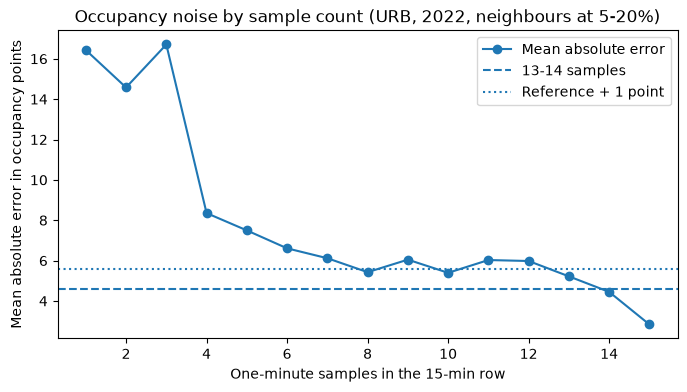

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    noise_curve["periodo_integracion"],
    noise_curve["mean_abs_error"],
    marker="o",
    label="Mean absolute error",
)
ax.axhline(reference_error, linestyle="--", label="13-14 samples")
ax.axhline(reference_error + 1, linestyle=":", label="Reference + 1 point")
ax.set(
    title="Occupancy noise by sample count (URB, 2022, neighbours at 5-20%)",
    xlabel="One-minute samples in the 15-min row",
    ylabel="Mean absolute error in occupancy points",
)
ax.legend()
plt.show()

E4c. What each k costs: the share of 2022 URB rows it would remove. First one month: rows per sample count.

In [30]:
def month_sample_counts(month_label: str) -> pl.DataFrame:
    # Number of URB rows per sample count in one month, without the clock-change rows.
    return (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{month_label}.parquet",  # one month's file
            columns=["tipo_elem","fecha","periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,  # urban points only
            ~pl.col("fecha").is_in(DST_ROWS),  # without the clock-change rows
        )
        .group_by("periodo_integracion")  # one group per sample count
        .agg(rows=pl.len())  #count the rows in each group
        .sort("periodo_integracion")  # sample counts from smallest to largest
    )


march_counts = month_sample_counts("2022-03")  # try on the trial month first
print(march_counts["rows"].sum())  # check: total rows in March
march_counts 

11422709


periodo_integracion,rows
i8,u32
1,33993
2,39181
3,68323
4,98580
5,76365
…,…
11,223753
12,280700
13,390395


All 12 months of 2022, added up per sample count.

In [31]:
sample_count_tables = []  # one small table per month
for month_label in MONTHS_2022:  # the 12 months of 2022
    sample_count_tables.append(month_sample_counts(month_label))
    print(month_label, "done")  # progress: one line per month

rows_by_samples_2022 = (
    pl.concat(sample_count_tables)  # the 12 tables stacked on top of each other
    .group_by("periodo_integracion")  # one group per sample count
    .agg(rows=pl.col("rows").sum()) 
    .sort("periodo_integracion")  # sample counts from smallest to largest
)
rows_by_samples_2022

2022-01 done
2022-02 done
2022-03 done
2022-04 done
2022-05 done
2022-06 done
2022-07 done
2022-08 done
2022-09 done
2022-10 done
2022-11 done
2022-12 done


periodo_integracion,rows
i8,u32
1,371322
2,443913
3,824061
4,1148138
5,858203
…,…
12,2916576
13,3996482
14,7146032


Check: no rows lost or added; sample counts run from 1 to 16 (16 = the kept autumn 02:00 rows).

In [32]:
print(pl.concat(sample_count_tables)["rows"].sum() == rows_by_samples_2022["rows"].sum()) 
print(rows_by_samples_2022["periodo_integracion"].min(), rows_by_samples_2022["periodo_integracion"].max())

True
1 16


The share of rows each k would remove.

In [33]:
total_rows_2022 = rows_by_samples_2022["rows"].sum()  # all 2022 URB rows, without clock-change rows

k_cost = (
    rows_by_samples_2022.with_columns(
        rows_removed=pl.col("rows").cum_sum() - pl.col("rows"),  # rows with fewer samples than this count
    )
    .with_columns(
        removed_percent=(pl.col("rows_removed") / total_rows_2022 * 100).round(2), 
    )
    .rename({"periodo_integracion": "k"})  # read each line as: "if k were this value"
    .select("k", "rows_removed", "removed_percent")  # only the columns we need
)

print(total_rows_2022)  # the base of the percent
with pl.Config(tbl_rows=20):  # show all lines, not "…"
    print(k_cost)

133474731
shape: (16, 3)
┌─────┬──────────────┬─────────────────┐
│ k   ┆ rows_removed ┆ removed_percent │
│ --- ┆ ---          ┆ ---             │
│ i8  ┆ u32          ┆ f64             │
╞═════╪══════════════╪═════════════════╡
│ 1   ┆ 0            ┆ 0.0             │
│ 2   ┆ 371322       ┆ 0.28            │
│ 3   ┆ 815235       ┆ 0.61            │
│ 4   ┆ 1639296      ┆ 1.23            │
│ 5   ┆ 2787434      ┆ 2.09            │
│ 6   ┆ 3645637      ┆ 2.73            │
│ 7   ┆ 4760405      ┆ 3.57            │
│ 8   ┆ 5985865      ┆ 4.48            │
│ 9   ┆ 7483926      ┆ 5.61            │
│ 10  ┆ 9159896      ┆ 6.86            │
│ 11  ┆ 11085450     ┆ 8.31            │
│ 12  ┆ 13400511     ┆ 10.04           │
│ 13  ┆ 16317087     ┆ 12.22           │
│ 14  ┆ 20313569     ┆ 15.22           │
│ 15  ┆ 27459601     ┆ 20.57           │
│ 16  ┆ 133471498    ┆ 100.0           │
└─────┴──────────────┴─────────────────┘


Noise and cost side by side, to choose k.

In [34]:
k_table = (
    noise_curve.select(
        pl.col("periodo_integracion").alias("k"),  # the sample count, read as a possible k
        pl.col("excess").round(2),  # how much noisier rows at this count are than the 13-14 rows
    )
    .join(k_cost, on=pl.col("k"))
)
with pl.Config(tbl_rows=20):
    print(k_table)

shape: (15, 4)
┌─────┬────────┬──────────────┬─────────────────┐
│ k   ┆ excess ┆ rows_removed ┆ removed_percent │
│ --- ┆ ---    ┆ ---          ┆ ---             │
│ i8  ┆ f64    ┆ u32          ┆ f64             │
╞═════╪════════╪══════════════╪═════════════════╡
│ 1   ┆ 11.85  ┆ 0            ┆ 0.0             │
│ 2   ┆ 9.99   ┆ 371322       ┆ 0.28            │
│ 3   ┆ 12.12  ┆ 815235       ┆ 0.61            │
│ 4   ┆ 3.77   ┆ 1639296      ┆ 1.23            │
│ 5   ┆ 2.91   ┆ 2787434      ┆ 2.09            │
│ 6   ┆ 2.02   ┆ 3645637      ┆ 2.73            │
│ 7   ┆ 1.53   ┆ 4760405      ┆ 3.57            │
│ 8   ┆ 0.84   ┆ 5985865      ┆ 4.48            │
│ 9   ┆ 1.46   ┆ 7483926      ┆ 5.61            │
│ 10  ┆ 0.81   ┆ 9159896      ┆ 6.86            │
│ 11  ┆ 1.44   ┆ 11085450     ┆ 8.31            │
│ 12  ┆ 1.4    ┆ 13400511     ┆ 10.04           │
│ 13  ┆ 0.63   ┆ 16317087     ┆ 12.22           │
│ 14  ┆ -0.14  ┆ 20313569     ┆ 15.22           │
│ 15  ┆ -1.75  ┆ 27459601     ┆ 20.

Found (2022, URB, neighbours at 5–20%): rows with 1–12 samples are 0.81–12.12 points noisier
than the 13–14 rows. 8 and 10 dip under 1 point (0.84, 0.81), but 9, 11 and 12 are above it again,
so the noise does not settle before 13 samples. From 13 samples on, every count is within 1 point.
k = 13 removes 12.22% of 2022 URB rows (16,317,087 of 133,474,731).

Catch: the curve only measures isolated short rows. Most short rows come in runs (March: only
189 of 33,993 1-sample rows had two complete neighbours).

Decision (*How k is chosen*): k = 13, keep rows with `periodo_integracion >= 13`. Not k = 8 or 10:
k only sets the lower end, so both would also keep the 9-, 11- and 12-sample rows, which are
1.40–1.46 points noisier. Report the 12.22% loss and the isolated-rows limitation.

If the panel in Step 4 loses many points because the removed rows push them below 90% availability,
revisit k with the reason written down.

## Step 4: the sensor panel
Keep one fixed list of measuring points per district, chosen on 2022, so district means change with traffic, not with points coming and going.

4a. Count each measuring point's valid readings, one month first.

In [ ]:
def month_valid_readings(month_label: str) -> pl.DataFrame:
    # Per URB measuring point: number of valid readings in one month.
    return (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{month_label}.parquet",  # one month's file
            columns=["id", "fecha", "tipo_elem", "intensidad", "ocupacion", "periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,  # urban measuring points only
            ~pl.col("fecha").is_in(DST_ROWS),  # without the clock-change rows
        )
        .group_by("id")  # one group per measuring point
        .agg(
            valid_readings=(
                pl.col("periodo_integracion") >= MIN_SAMPLES
                & pl.col("ocupacion").is_not_null()  # occupancy present
                & pl.col("intensidad").is_not_null()  #  flow presents
            ).sum(),  # True = 1, False = 0, so the sum counts the valid rows
        )
        .sort("id")  # measuring points in id order
    )


march_valid = month_valid_readings("2022-03")  # try on the trial month first
print(march_valid.height)
print(march_valid["valid_readings"].sum())  # all valid readings in March
march_valid.describe() 

3989
11422709


statistic,id,valid_readings
str,f64,f64
"""count""",3989.0,3989.0
"""null_count""",0.0,0.0
"""mean""",6385.89095,2863.552018
"""std""",2411.20472,340.783863
"""min""",3395.0,1.0
"""25%""",4578.0,2900.0
"""50%""",5649.0,2960.0
"""75%""",7023.0,2969.0
"""max""",10965.0,2972.0
